# Wikipedia recommender system

This system takes a list of Wikipedia articles someone has read and recommends similar ones, each with a score and an explanation.

| Step | What it does | Saved in |
|---|---|---|
| 1. Crawl and scrape | downloads 3,000 articles | `data/raw_articles.parquet` |
| 2. Lemmatize | cleans each article's words | `data/articles.parquet` |
| 3. TF-IDF | turns each article into a vector, `{word: weight}` | memory only |
| 4. Recommend | scores every article against what was read | |
| 5. Statistics | describes the database | |
| 6. Examples | shows recommendations and why they were chosen | |

Setup: `pip install -r requirements.txt`, then `python -m spacy download en_core_web_sm`.

In [1]:
import math
import time
from collections import Counter, deque
from pathlib import Path
from urllib.parse import unquote

import matplotlib.pyplot as plt
import pandas as pd
import requests
import spacy
from bs4 import BeautifulSoup

BASE_URL = "https://en.wikipedia.org/wiki/"
RAW_PATH = Path("data/raw_articles.parquet")
LEMMAS_PATH = Path("data/articles.parquet")
RAW_PATH.parent.mkdir(exist_ok=True)

---
# 1. Crawling and scraping

**Scraping** turns a page into clean text, using `requests` to download it and `BeautifulSoup` to search its HTML. An article's prose is in `<p>` tags, while references and navigation are mostly lists and tables, so we keep only `<p>` tags. Citation numbers, tables and formulas are deleted first.

In [2]:
HEADERS = {"User-Agent": "WikiRecommenderCourseProject/0.1 (educational project; python-requests)"}


def download_page(title):
    """Takes an article title. Returns the page's HTML, or None if the download fails."""
    try:
        response = requests.get(BASE_URL + title.replace(" ", "_"), headers=HEADERS, timeout=30)
    except requests.RequestException:
        return None
    return response.text if response.status_code == 200 else None


def parse_article(html):
    """Takes a page's HTML. Returns a dict with the article's title, text, n_words and links."""
    soup = BeautifulSoup(html, "lxml")
    body = soup.select_one("#mw-content-text")

    # Citation numbers, tables and formulas aren't prose.
    for element in body.select("sup, table, .mwe-math-element"):
        element.decompose()

    paragraphs = body.find_all("p")
    text = "\n".join(p.get_text().strip() for p in paragraphs)

    links = []
    for p in paragraphs:
        for link in p.select("a[href*='/wiki/']"):
            target = unquote(link["href"].split("/wiki/")[1].split("#")[0]).replace("_", " ")
            if ":" not in target and not target.startswith("List of") and target not in links:
                links.append(target)

    return {
        "title": soup.select_one("#firstHeading").get_text(),
        "text": text,
        "n_words": len(text.split()),
        "links": links,
    }

**Crawling** finds the pages. It starts from 5 seed articles in each of 10 fields. For each field, it takes the first title from a queue, saves the article if it has at least 200 words, and adds its first 40 links to the end of the queue, until the field has 300 articles. New links wait at the end, so articles close to the seeds come first (**breadth-first** search). The word limit also removes most disambiguation and index pages.

In [3]:
SEEDS = {
    "physics_space": ["Black hole", "Quantum mechanics", "General relativity", "Solar System", "Dark matter"],
    "biology_medicine": ["DNA", "Evolution", "Cell (biology)", "Vaccine", "Photosynthesis"],
    "computing": ["Machine learning", "Algorithm", "Operating system", "Computer network", "Programming language"],
    "history": ["Roman Empire", "World War II", "French Revolution", "Ottoman Empire", "Ancient Egypt"],
    "music": ["Jazz", "Classical music", "Hip-hop", "The Beatles", "Rock music"],
    "film_literature": ["Film noir", "Alfred Hitchcock", "Science fiction", "William Shakespeare", "Novel"],
    "sport": ["Association football", "Basketball", "Olympic Games", "Tennis", "Formula One"],
    "food": ["Italian cuisine", "Coffee", "Wine", "Baking", "Fermentation in food processing"],
    "economics": ["Inflation", "Supply and demand", "Stock market", "Keynesian economics", "Central bank"],
    "earth_nature": ["Volcano", "Amazon rainforest", "Plate tectonics", "Climate change", "Ocean"],
}
MIN_WORDS = 200


def crawl(seeds, per_field=300, links_per_page=40):
    """Takes {field: seed titles}. Returns a list of article dicts."""
    articles = {}
    visited = set()

    for field, seed_titles in seeds.items():
        queue = deque(seed_titles)
        count = 0
        while queue and count < per_field:
            title = queue.popleft()
            if title in visited:
                continue
            visited.add(title)

            html = download_page(title)
            time.sleep(0.1)  # avoids overloading Wikipedia's servers
            if html is None:
                continue
            article = parse_article(html)

            # The second check catches redirects to an article we already have.
            if article["n_words"] < MIN_WORDS or article["title"] in articles:
                continue
            article["field"] = field
            articles[article["title"]] = article
            queue.extend(article["links"][:links_per_page])
            count += 1
        print(f"{field}: {count} articles")

    return list(articles.values())

The crawl took 27 minutes, so the result is saved, and this cell only crawls again if the file is missing. Wikipedia refused 108 of the 3,323 requests for coming too fast, and those pages were skipped. Each row is one article, and its text is still one long string.

In [4]:
if RAW_PATH.exists():
    raw = pd.read_parquet(RAW_PATH)
else:
    raw = pd.DataFrame(crawl(SEEDS))
    raw.to_parquet(RAW_PATH)

print("rows, columns:", raw.shape)
raw[["title", "field", "n_words"]].head(3)

rows, columns: (3000, 5)


,title,field,n_words
0,Black hole,physics_space,10838
1,Quantum mechanics,physics_space,6467
2,General relativity,physics_space,9083


---
# 2. Lemmatization

Lemmatization reduces each word to its dictionary form, so `holes` becomes `hole`. We chose it over stemming because it gives real words: "studies" becomes `study`, not `studi`, and our explanations show these words to the reader.

We keep a lemma only if it isn't a stop word, is longer than one character, starts with a letter, and contains only letters and digits. `LEMMA_FIXES` corrects spaCy's most frequent mistakes, such as "species" becoming `specie`, which means coins.

In [5]:
nlp = spacy.load("en_core_web_sm", exclude=["parser", "ner"])

LEMMA_FIXES = {
    "specie": "species", "subspecie": "subspecies", "datum": "data", "physic": "physics",
    "astrophysic": "astrophysics", "mechanic": "mechanics", "mathematic": "mathematics",
    "politic": "politics", "statistic": "statistics", "instal": "install", "wag": "wage",
    "antibodie": "antibody", "infrare": "infrared", "speciman": "specimen", "diabete": "diabetes",
    "filmmake": "filmmaking", "winemake": "winemaking",
}


def clean_lemmas(doc):
    """Takes a spaCy Doc. Returns the list of its cleaned lemmas."""
    lemmas = []
    for token in doc:
        lemma = token.lemma_.lower()
        if lemma not in nlp.Defaults.stop_words and len(lemma) > 1 and lemma[0].isalpha() and lemma.isalnum():
            lemmas.append(LEMMA_FIXES.get(lemma, lemma))
    return lemmas


# Takes about 2 minutes, so the result is saved too.
if LEMMAS_PATH.exists():
    articles = pd.read_parquet(LEMMAS_PATH)
else:
    docs = nlp.pipe(raw["text"], n_process=8, batch_size=16)
    articles = raw.copy()
    articles["lemmas"] = [" ".join(clean_lemmas(doc)) for doc in docs]
    articles.to_parquet(LEMMAS_PATH)

print(clean_lemmas(nlp("Black holes were formed by collapsing stars in 1915.")))

['black', 'hole', 'form', 'collapse', 'star']


---
# 3. TF-IDF, written by hand

Each article becomes a vector of word weights. A word gets a high weight if it's frequent in this article but rare in the others. For a word in an article, out of $N$ articles:

$$\text{weight} = \underbrace{\left(1 + \ln(\text{count in the article})\right)}_{\text{tf}} \times \underbrace{\ln\frac{N}{\text{articles containing the word}}}_{\text{idf}}$$

- **idf** removes words used everywhere. A word in every article gets $\ln(1) = 0$.
- **The logarithm in tf** stops one word from taking over. With plain counts, `coffee` gets a weight of 0.93 in the Coffee vector, and with the logarithm it gets 0.11.
- **Normalizing** divides the weights by the vector's length, $\sqrt{\sum \text{weight}^2}$, so long articles have no advantage.

Only words in at least 5 articles are kept, because a word in one article can't connect two articles.

We compare vectors with **cosine similarity**. For vectors of length 1, it's the sum of the products of their weights, so only shared words count. A score of 0 means no shared words, and 1 means the same mix of words:

$$\text{similarity}(a, b) = \sum_{\text{word}} a_{\text{word}} \times b_{\text{word}}$$

In [6]:
def compute_idf(all_counts, min_articles=5):
    """Takes the word counts of each article. Returns {word: idf}."""
    articles_with_word = Counter()
    for counts in all_counts:
        articles_with_word.update(counts.keys())
    n = len(all_counts)
    return {word: math.log(n / df) for word, df in articles_with_word.items() if df >= min_articles}


def normalize(vector):
    """Takes a vector. Returns it scaled to length 1."""
    length = math.sqrt(sum(weight ** 2 for weight in vector.values()))
    return {word: weight / length for word, weight in vector.items()}


def tfidf_vector(counts, idf):
    """Takes one article's word counts and the idf. Returns the article's vector."""
    return normalize({word: (1 + math.log(count)) * idf[word] for word, count in counts.items() if word in idf})


def similarity(a, b):
    """Takes two vectors of length 1. Returns their cosine similarity."""
    return sum(weight * b[word] for word, weight in a.items() if word in b)

Here's one article at each step. `coffee` has the highest count, but it isn't the top word in the vector, because many other articles use it too.

In [7]:
all_counts = [Counter(lemmas.split()) for lemmas in articles["lemmas"]]
idf = compute_idf(all_counts)
vectors = {title: tfidf_vector(counts, idf) for title, counts in zip(articles["title"], all_counts)}

coffee = articles[articles["title"] == "Coffee"].iloc[0]
print("text:  ", coffee["text"].strip()[:70], "...")
print("lemmas:", coffee["lemmas"][:70], "...")
print("counts:", Counter(coffee["lemmas"].split()).most_common(4))
print("vector:", [(word, round(weight, 3)) for word, weight in Counter(vectors["Coffee"]).most_common(4)])

text:   Coffee is a beverage brewed from roasted, ground coffee beans. Dark-co ...
lemmas: coffee beverage brew roasted ground coffee bean dark colored bitter co ...
counts: [('coffee', 341), ('bean', 42), ('water', 33), ('century', 32)]
vector: [('arabica', 0.128), ('robusta', 0.118), ('caffeine', 0.112), ('coffee', 0.111)]


---
# 4. The recommender

The vectors of the articles read are added together and normalized into one **profile** vector. Each other article's **score** is its similarity to the profile, and the highest scores are recommended. Any English article can be used as input: if it isn't in the database, it's downloaded and processed on the spot.

In [8]:
def build_profile(visited):
    """Takes {title: vector} for the articles read. Returns one vector for the reader."""
    total = Counter()
    for vector in visited.values():
        total.update(vector)
    return normalize(total)


def word_contributions(profile, vector):
    """Takes two vectors. Returns a Counter with each shared word's part of their similarity."""
    return Counter({word: weight * vector[word] for word, weight in profile.items() if word in vector})


def read_articles(items):
    """Takes a list of titles or links. Returns {title: vector}."""
    visited = {}
    for item in items:
        title = item.split("/wiki/")[-1].replace("_", " ")
        if title in vectors:
            visited[title] = vectors[title]
            continue
        html = download_page(title)
        article = parse_article(html) if html else None
        if article is None or article["n_words"] < MIN_WORDS:
            print(f"Skipped {item!r}: no article found")
            continue
        visited[article["title"]] = tfidf_vector(Counter(clean_lemmas(nlp(article["text"]))), idf)
    if not visited:
        raise ValueError("None of these articles could be found.")
    return visited


def recommend(visited, top_n=10):
    """Takes {title: vector} for the articles read. Returns a table of the best matches."""
    profile = build_profile(visited)
    scores = {title: similarity(profile, vector) for title, vector in vectors.items() if title not in visited}

    rows = []
    for title in sorted(scores, key=scores.get, reverse=True)[:top_n]:
        shared_words = word_contributions(profile, vectors[title]).most_common(5)
        rows.append({
            "title": title,
            "score": round(scores[title], 3),
            "top shared words": ", ".join(word for word, _ in shared_words),
            "url": BASE_URL + title.replace(" ", "_"),
        })
    return pd.DataFrame(rows)

Here's how one article gets its score. Each word's contribution is its weight in the profile times its weight in the article, and adding all of them gives the score. Only the 5 largest are shown.

In [9]:
example_profile = build_profile(read_articles(["Black hole", "General relativity"]))
example_article = vectors["Neutron star"]
shared_words = word_contributions(example_profile, example_article)

for word, contribution in shared_words.most_common(5):
    print(f"{word:<14} {example_profile[word]:.3f} x {example_article[word]:.3f} = {contribution:.4f}")
print(f"\nAll {len(shared_words)} shared words add up to the score: {sum(shared_words.values()):.3f}")

pulsar         0.080 x 0.148 = 0.0119
neutron        0.070 x 0.143 = 0.0100
ligo           0.073 x 0.099 = 0.0072
gravitational  0.089 x 0.080 = 0.0071
relativity     0.100 x 0.061 = 0.0061

All 682 shared words add up to the score: 0.426


---
# 5. Statistics about the database

Cleaning removes a bit under half of all words, mostly stop words. Most different lemmas are rare, often names or foreign words, so the vocabulary is far smaller than the full list, yet it still covers almost all of the text.

Most articles are fairly short, and a few are very long, which is why vectors are normalized.

words scraped: 12,052,971
lemmas kept: 6,390,615
different lemmas: 162,493, of which in at least 5 articles: 35,439
those 35,439 cover 95.8% of the text


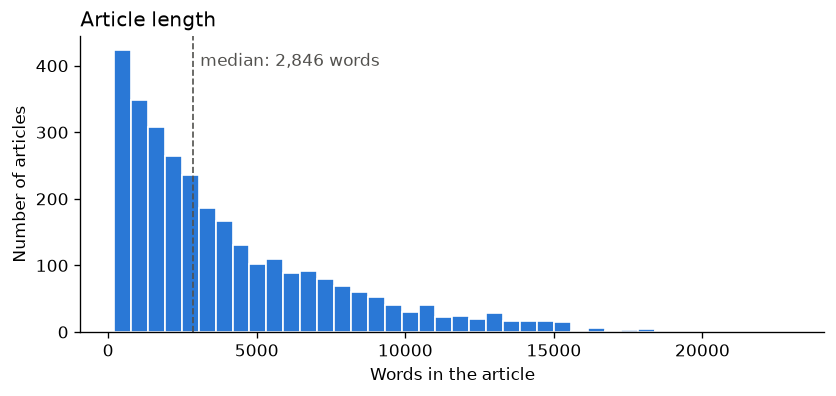

In [10]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, LIGHT_GRAY, DARK_GRAY = COLORS[0], "#c3c2b7", "#52514e"
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left"})

word_totals = Counter()
for counts in all_counts:
    word_totals.update(counts)
print(f"words scraped: {articles['n_words'].sum():,}")
print(f"lemmas kept: {sum(word_totals.values()):,}")
print(f"different lemmas: {len(word_totals):,}, of which in at least 5 articles: {len(idf):,}")
print(f"those {len(idf):,} cover {sum(word_totals[word] for word in idf) / sum(word_totals.values()):.1%} of the text")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(articles["n_words"], bins=40, color=BLUE, edgecolor="white")
ax.axvline(articles["n_words"].median(), color=DARK_GRAY, linestyle="--", linewidth=1)
ax.text(articles["n_words"].median() + 250, ax.get_ylim()[1] * 0.9, f"median: {articles['n_words'].median():,.0f} words", color=DARK_GRAY)
ax.set(title="Article length", xlabel="Words in the article", ylabel="Number of articles")
plt.show()

The most frequent words aren't the most useful ones. Common words like `use` and `include` say little about a topic, so in the TF-IDF ranking, words like `theory`, `water` and `music` take their place.

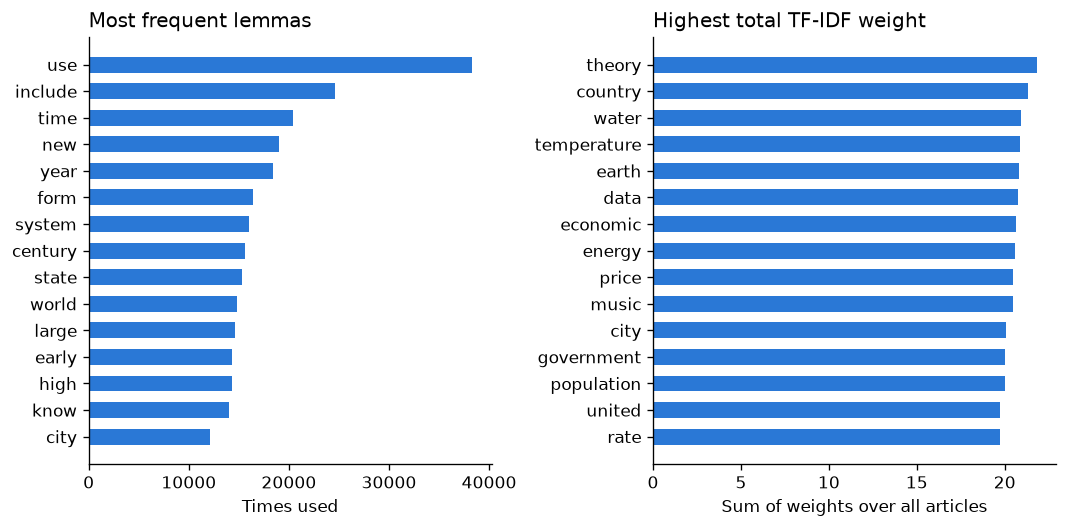

In [11]:
tfidf_totals = Counter()
for vector in vectors.values():
    tfidf_totals.update(vector)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, totals, title, xlabel in [
    (axes[0], word_totals, "Most frequent lemmas", "Times used"),
    (axes[1], tfidf_totals, "Highest total TF-IDF weight", "Sum of weights over all articles"),
]:
    words, values = zip(*totals.most_common(15))
    ax.barh(words, values, height=0.6, color=BLUE)
    ax.invert_yaxis()
    ax.set(title=title, xlabel=xlabel)
plt.tight_layout()
plt.show()

To compare articles with each other, we use a sample of 30 articles per field, because comparing all 3,000 would take about 4.5 million comparisons. Each field is most similar to itself, which is a good sign, because the recommender never sees the field labels. The labels only record which seeds led to an article, so they aren't always its true topic.

average similarity of 44,850 pairs: same field 0.080, different fields 0.037


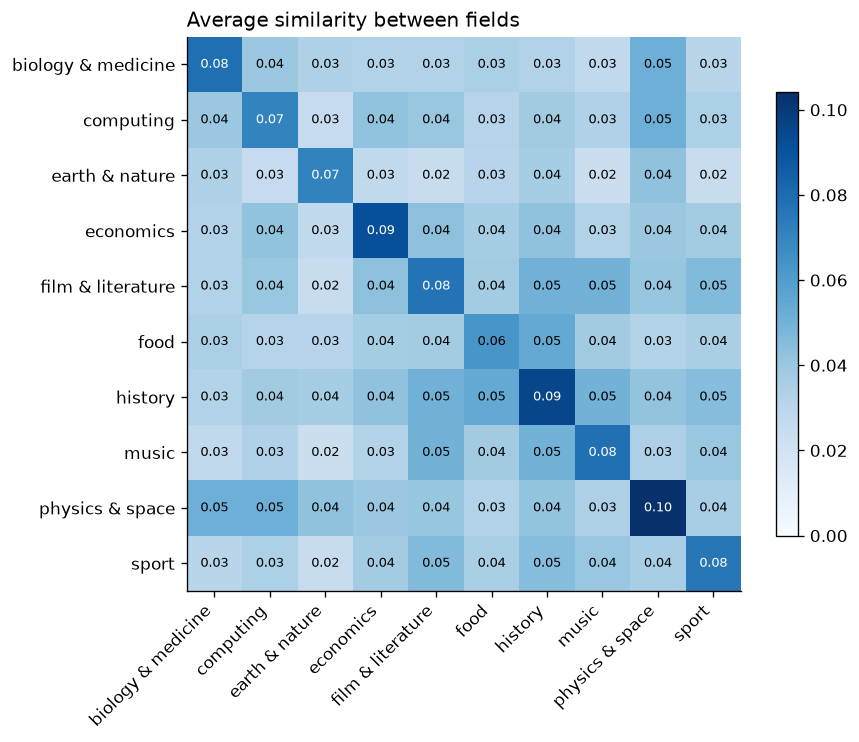

In [12]:
sample = articles.groupby("field").sample(30, random_state=42)
sample_titles = sample["title"].tolist()
sample_fields = [field.replace("_", " & ") for field in sample["field"]]

rows = []
for i in range(len(sample_titles)):
    for j in range(i + 1, len(sample_titles)):
        score = similarity(vectors[sample_titles[i]], vectors[sample_titles[j]])
        rows.append((sample_titles[i], sample_titles[j], sample_fields[i], sample_fields[j], score))
pairs = pd.DataFrame(rows, columns=["first", "second", "first field", "second field", "similarity"])

same_field = pairs["first field"] == pairs["second field"]
print(f"average similarity of {len(pairs):,} pairs: same field {pairs[same_field]['similarity'].mean():.3f}, different fields {pairs[~same_field]['similarity'].mean():.3f}")

both_ways = pd.concat([pairs, pairs.rename(columns={"first field": "second field", "second field": "first field"})])
matrix = both_ways.pivot_table(index="first field", columns="second field", values="similarity")

fig, ax = plt.subplots(figsize=(7.5, 6))
image = ax.imshow(matrix, cmap="Blues", vmin=0)
ax.set_xticks(range(len(matrix)), matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(matrix)), matrix.index)
for row in range(len(matrix)):
    for column in range(len(matrix)):
        value = matrix.iloc[row, column]
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=8, color="white" if value > 0.065 else "black")
ax.set_title("Average similarity between fields")
fig.colorbar(image, ax=ax, shrink=0.8)
plt.show()

The most similar pairs in the sample are closely related topics:

In [13]:
pairs.nlargest(5, "similarity")[["first", "second", "similarity"]].round(3).reset_index(drop=True)

,first,second,similarity
0,Dacite,Andesite,0.444
1,Innate immune system,Adaptive immune system,0.441
2,Mathematical formulation of quantum mechanics,Quantization (physics),0.437
3,Lord Chamberlain's Men,King's Men (playing company),0.430
4,IS–LM model,Neoclassical synthesis,0.412


---
# 6. Examples with explanations

`plot_recommendations` shows the top articles and their scores, with each bar split by how much of the score came from each article read.

`plot_breakdown` is a **prediction breakdown** for one recommended article: starting from 0, each word adds its contribution until the bars reach the final score.

In [14]:
def plot_recommendations(visited, top_n=10):
    """Takes the articles read. Draws the top recommendations, split by which article read they came from."""
    table = recommend(visited, top_n)
    fig, ax = plt.subplots(figsize=(9, 0.4 * top_n + 1.2))

    for row, (title, score) in enumerate(zip(table["title"], table["score"])):
        parts = [similarity(vector, vectors[title]) for vector in visited.values()]
        left = 0
        for i, (name, part) in enumerate(zip(visited, parts)):
            # Only 8 colors are distinct enough, so any further articles are gray.
            color = COLORS[i] if i < len(COLORS) else LIGHT_GRAY
            width = part / sum(parts) * score
            ax.barh(row, width, left=left, height=0.6, color=color, edgecolor="white", label=name if row == 0 and i < len(COLORS) else None)
            left += width
        ax.text(left + 0.005, row, f"{score:.3f}", va="center")

    ax.set_yticks(range(len(table)), table["title"])
    ax.invert_yaxis()
    ax.set(title="Top recommendations", xlabel="Score")
    ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5), title="Part of the score from:")
    plt.show()


def plot_breakdown(visited, title, top_n=10):
    """Takes the articles read and one title. Draws how the words build up that article's score."""
    contributions = word_contributions(build_profile(visited), vectors[title])
    top_words = contributions.most_common(top_n)
    score = sum(contributions.values())
    other_words = score - sum(value for _, value in top_words)
    rows = top_words + [(f"{len(contributions) - len(top_words)} other shared words", other_words)]

    fig, ax = plt.subplots(figsize=(9, 0.33 * len(rows) + 1.6))
    left = 0
    for row, (word, value) in enumerate(rows):
        ax.barh(row, value, left=left, height=0.6, color=BLUE if row < len(top_words) else LIGHT_GRAY)
        ax.text(left + value + score * 0.01, row, f"+{value:.3f}", va="center")
        left += value
    ax.barh(len(rows), score, height=0.6, color=DARK_GRAY)
    ax.text(score + score * 0.01, len(rows), f"{score:.3f}", va="center", fontweight="bold")

    ax.set_yticks(range(len(rows) + 1), [word for word, _ in rows] + ["final score"])
    ax.invert_yaxis()
    ax.set_xlim(0, score * 1.15)
    ax.set(title=f"Why '{title}' scored {score:.3f}", xlabel="Score")
    plt.show()

## Try it

**Change this list and run the cell.** Use titles, links, or both.

In [15]:
MY_ARTICLES = [
    "Black hole",
    "https://en.wikipedia.org/wiki/General_relativity",
]

visited = read_articles(MY_ARTICLES)
recommendations = recommend(visited)
recommendations

,title,score,top shared words,url
0,Tests of general relativity,0.500,"relativity, pulsar, gravitational, einstein, r...",https://en.wikipedia.org/wiki/Tests_of_general...
1,Gravitational wave,0.472,"pulsar, ligo, spacetime, gravitational, superm...",https://en.wikipedia.org/wiki/Gravitational_wave
2,Gravity,0.457,"relativity, spacetime, gravitational, einstein...",https://en.wikipedia.org/wiki/Gravity
3,Supermassive black hole,0.455,"supermassive, schwarzschild, hole, quasar, galaxy",https://en.wikipedia.org/wiki/Supermassive_bla...
4,Alternatives to general relativity,0.453,"relativity, singularity, gravitational, spacet...",https://en.wikipedia.org/wiki/Alternatives_to_...
5,Gravitational singularity,0.452,"singularity, spacetime, schwarzschild, relativ...",https://en.wikipedia.org/wiki/Gravitational_si...
6,Hawking radiation,0.444,"schwarzschild, hawk, hole, horizon, spacetime",https://en.wikipedia.org/wiki/Hawking_radiation
7,Event horizon,0.442,"schwarzschild, horizon, spacetime, singularity...",https://en.wikipedia.org/wiki/Event_horizon
8,Curved spacetime,0.432,"spacetime, relativity, curvature, gravitationa...",https://en.wikipedia.org/wiki/Curved_spacetime
9,Neutron star,0.426,"pulsar, neutron, ligo, gravitational, relativity",https://en.wikipedia.org/wiki/Neutron_star


The top recommendation shares specific physics vocabulary with both articles, like `relativity` and `gravitational`. No single word decides its score: the top 10 words add up to only a small part, and most comes from hundreds of smaller shared words.

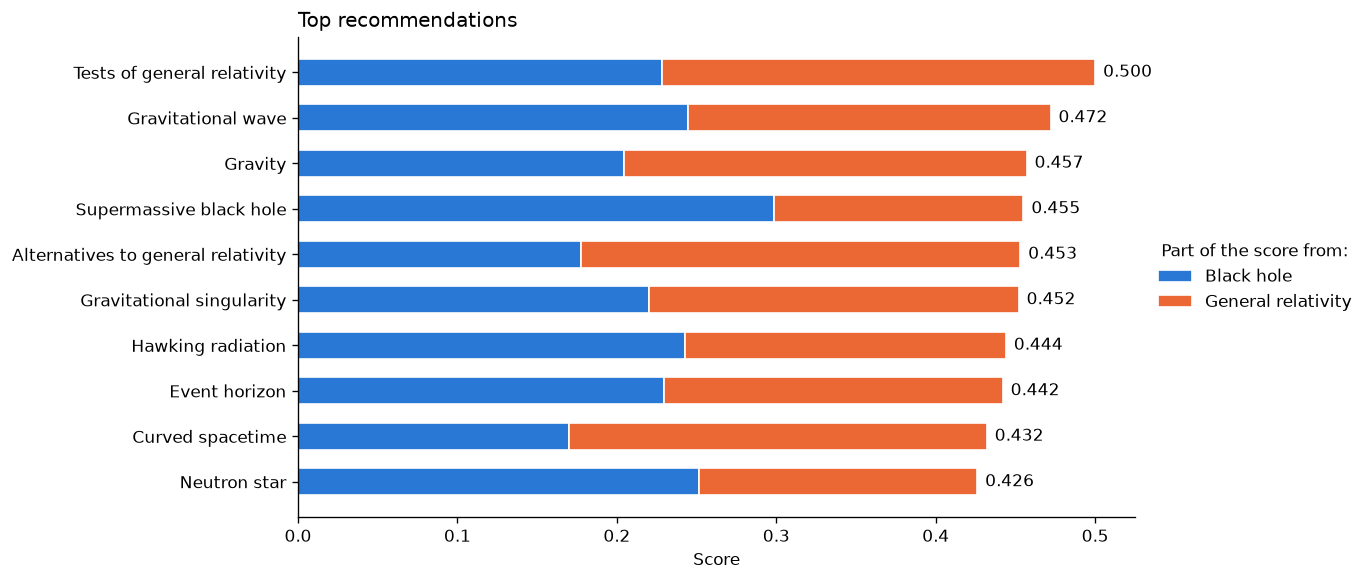

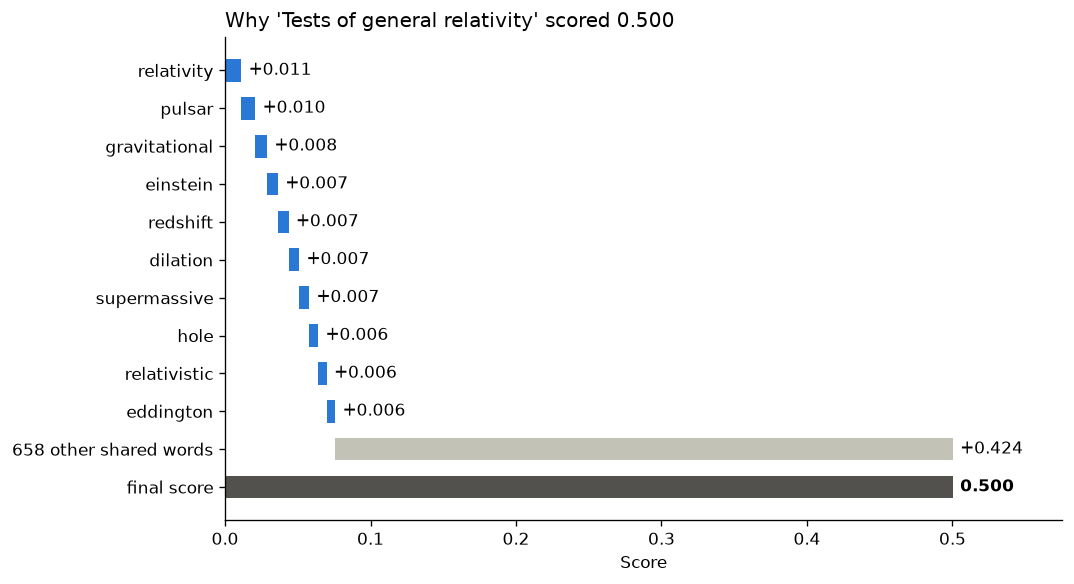

In [16]:
plot_recommendations(visited)
plot_breakdown(visited, recommendations["title"][0])

## Example: two unrelated topics

The profile sits between the two topics, so articles from either one can score well. Here, 9 of the top 10 are about space and physics, and only "History of coffee" is about coffee. Most of each score comes from just one of the two articles read.

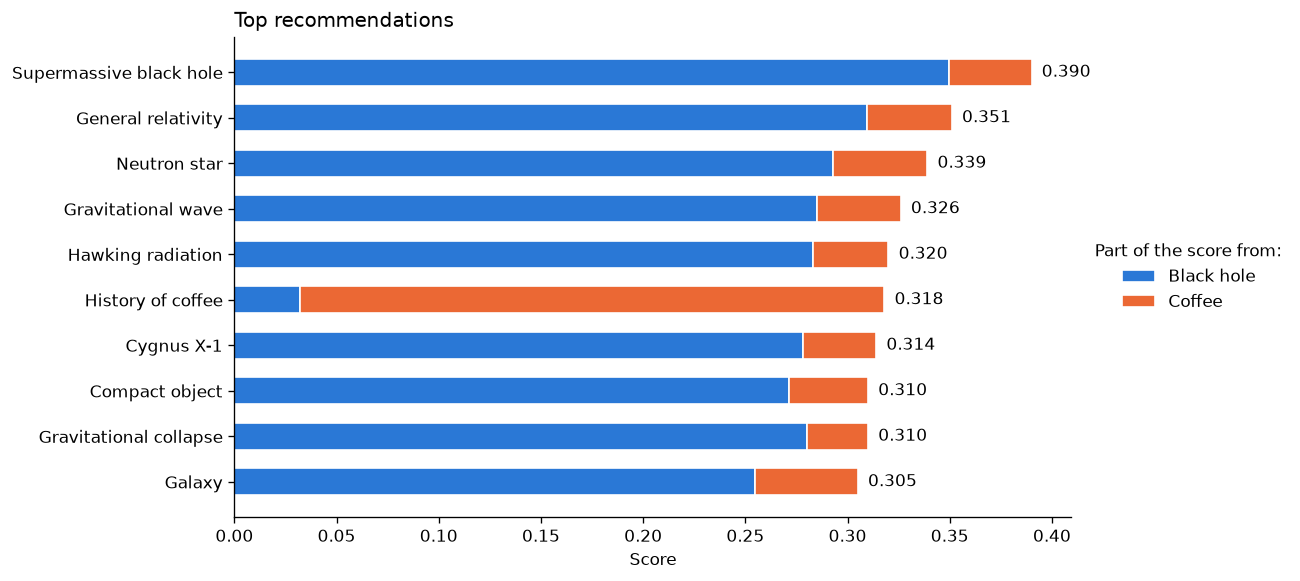

In [17]:
plot_recommendations(read_articles(["Black hole", "Coffee"]))

## Example: an article that isn't in the database

"Moka pot" isn't in the database, so it's downloaded first. With a narrow topic like this one, the top 10 words make up most of the score, unlike in the Black hole example.

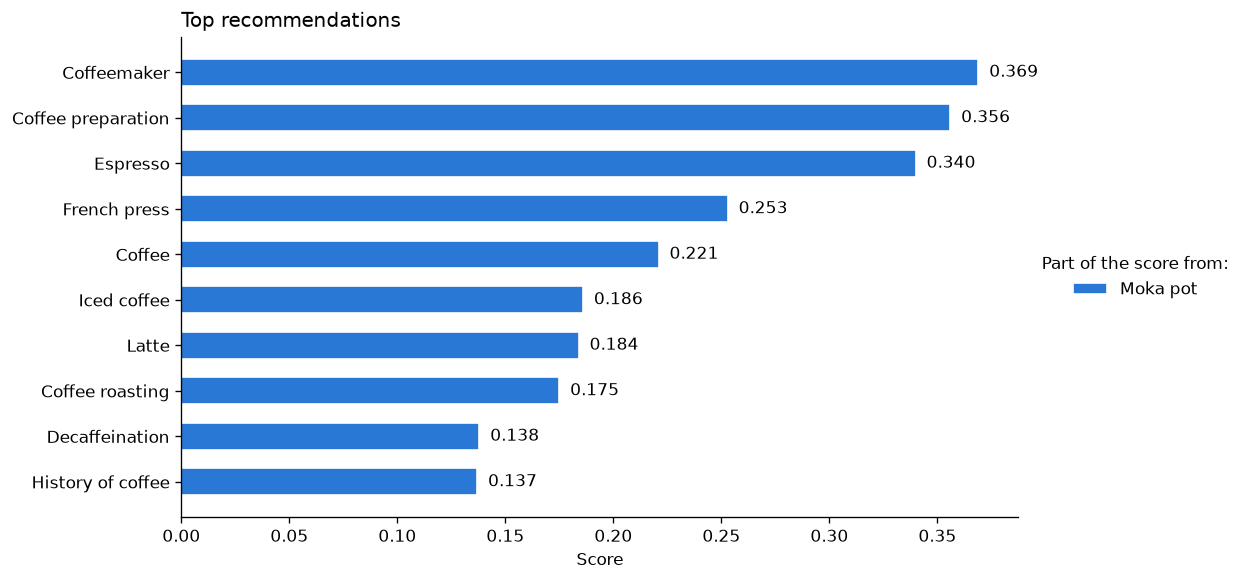

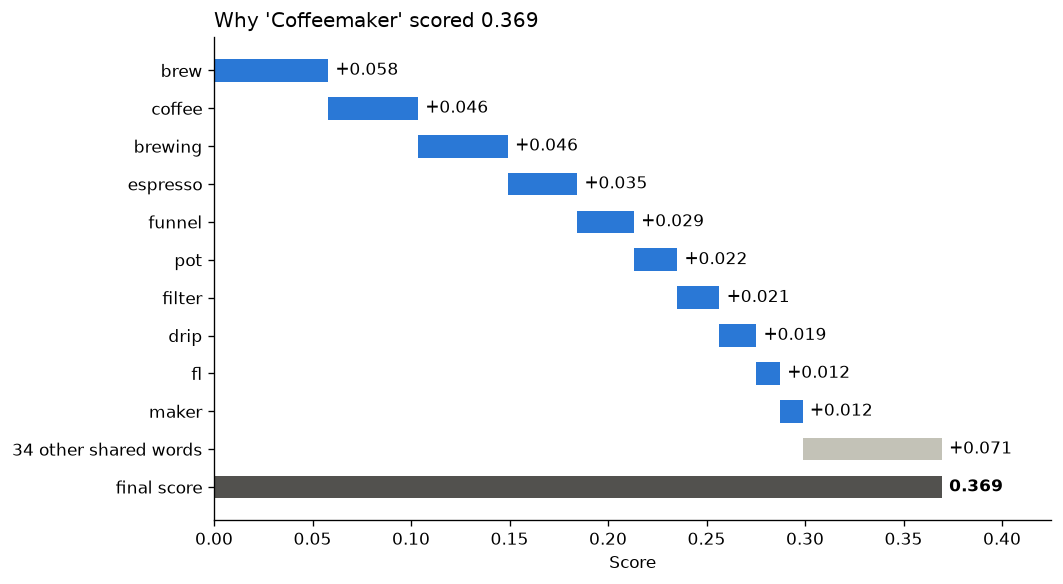

In [18]:
moka = read_articles(["Moka pot"])
plot_recommendations(moka)
plot_breakdown(moka, recommend(moka)["title"][0])

## Limitations

- **Exact words only.** "car" and "automobile" count as unrelated words, and "New York" becomes `new` and `york`.
- **Lemmatization isn't perfect.** `LEMMA_FIXES` only covers the most frequent mistakes, and "Hawking" can become `hawk`.
- **Only saved articles can be recommended**, and only English Wikipedia works as input.
- **Mixed interests are averaged**, so one topic can dominate the list.